# Step 1 : Frame the Problem



## 1. Business Question
What factors are associated with salary differences in data and AI jobs?

The goal is to explore how salary varies with job title, experience level, employment type, work arrangement, employee residence, company location, and company size.

## 2. Unit of Observation
One row represents one salary record for a job position.

Before analysis, check whether duplicate rows exist and whether multiple records represent different employees, different salary observations, or repeated entries.

## 3. Target Variable
- **Target:** `salary_in_usd`
- **Type:** Numeric (continuous)
- **Meaning:** Salary expressed in US dollars.

The primary objective is to understand salary distributions and identify factors associated with salary differences.

## 4. Time Column
- **Column:** `work_year`
- **Type:** Temporal / discrete year
- **Purpose:** Analyze salary trends across years and check whether comparisons are affected by changes over time.

## 5. Known Limitations
- The dataset's collection method and sampling process must be verified.
- The available records may not represent every data and AI professional or job market.
- Salary may depend on factors not included in the dataset, such as industry, education, and years of experience.
- `employee_residence` and `company_location` represent different geographic dimensions.
- The meaning and encoding of `remote_ratio` should be verified using the data dictionary.
- Currency conversion, salary period, and missing-value conventions should be checked before analysis.

## 6. Hypotheses
1. Senior-level roles tend to have higher salaries than entry-level roles.
2. Salary distributions differ across job titles.
3. Salary varies by company location and employee residence.
4. Salary distributions differ across company sizes.
5. Remote work arrangements are associated with salary differences.

These are hypotheses to investigate, not conclusions.

## Initial Analysis Plan
1. Inspect column types, missing values, and duplicate records.
2. Validate category definitions and salary units.
3. Examine salary distributions and outliers.
4. Compare salary across experience levels, job titles, locations, and company sizes.
5. Investigate year-over-year salary trends.
6. If predictive modeling is required, define the prediction objective and prevent data leakage.


In [226]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Step 2 : Take a First Look

In [227]:
df = pd.read_csv("../data/ds_salaries.csv")

df.shape

df.head() 

df.sample(5, random_state=0) 

df.info() 

df.nunique() 


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           3755 non-null   int64 
 1   experience_level    3755 non-null   object
 2   employment_type     3755 non-null   object
 3   job_title           3755 non-null   object
 4   salary_in_usd       3755 non-null   int64 
 5   employee_residence  3755 non-null   object
 6   remote_ratio        3755 non-null   int64 
 7   company_location    3755 non-null   object
 8   company_size        3755 non-null   object
dtypes: int64(3), object(6)
memory usage: 264.2+ KB


work_year                4
experience_level         4
employment_type          4
job_title               93
salary_in_usd         1035
employee_residence      78
remote_ratio             3
company_location        72
company_size             3
dtype: int64

# Convert categorical columns to category dtype

In [228]:
categorical_columns = [
    "experience_level",
    "employment_type",
    "job_title",
    "employee_residence",
    "company_location",
    "company_size",
]

for col in categorical_columns:
    df[col] = df[col].astype("category")

# Verify the changes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   work_year           3755 non-null   int64   
 1   experience_level    3755 non-null   category
 2   employment_type     3755 non-null   category
 3   job_title           3755 non-null   category
 4   salary_in_usd       3755 non-null   int64   
 5   employee_residence  3755 non-null   category
 6   remote_ratio        3755 non-null   int64   
 7   company_location    3755 non-null   category
 8   company_size        3755 non-null   category
dtypes: category(6), int64(3)
memory usage: 118.7 KB


In [229]:

df["remote_ratio"] = df["remote_ratio"].map({
    0: "On-site",
    50: "Hybrid",
    100: "Fully remote",
}).astype("category")


df["remote_ratio"].value_counts(dropna=False)


remote_ratio
On-site         1923
Fully remote    1643
Hybrid           189
Name: count, dtype: int64

# Step 3 : Assess Data Quality

In [230]:
# Missing values
miss = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print(miss[miss > 0])

# Duplicates
print("Rows before:", len(df))

df = df.drop_duplicates()

print("Rows after:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

Series([], dtype: float64)
Rows before: 3755
Rows after: 2584
Remaining duplicates: 0


# Clean inconsistent text labels


In [231]:
text_columns = [
    "experience_level",
    "employment_type",
    "job_title",
    "employee_residence",
    "company_location",
    "company_size"
]

for col in text_columns:
    df[col] = df[col].str.strip()

# Standardize categorical codes
for col in [
    "experience_level",
    "employment_type",
    "employee_residence",
    "company_location",
    "company_size"
]:
    df[col] = df[col].str.upper()

# Check unique values
for col in text_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


experience_level:
experience_level
SE    1554
MI     664
EN     270
EX      96
Name: count, dtype: int64

employment_type:
employment_type
FT    2547
PT      17
CT      10
FL      10
Name: count, dtype: int64

job_title:
job_title
Data Engineer                598
Data Scientist               538
Data Analyst                 396
Machine Learning Engineer    206
Analytics Engineer            91
                            ... 
Principal Data Architect       1
Head of Machine Learning       1
Cloud Data Architect           1
Staff Data Scientist           1
Finance Data Analyst           1
Name: count, Length: 93, dtype: int64

employee_residence:
employee_residence
US    1893
GB     150
CA      81
IN      70
DE      47
      ... 
RS       1
NZ       1
MD       1
LU       1
MT       1
Name: count, Length: 78, dtype: int64

company_location:
company_location
US    1929
GB     155
CA      83
IN      57
DE      55
      ... 
CN       1
NZ       1
CL       1
MD       1
MT       1
Name: count

# Step 4 : Study Numeric Variables One at a Time

,count,mean,std,min,25%,50%,75%,max
work_year,2584.0,2022.301084,0.749179,2020.0,2022.0,2022.0,2023.0,2023.0
salary_in_usd,2584.0,133409.280186,67136.837329,5132.0,84975.0,130000.0,175000.0,450000.0


work_year       -0.97
salary_in_usd    0.62
dtype: float64

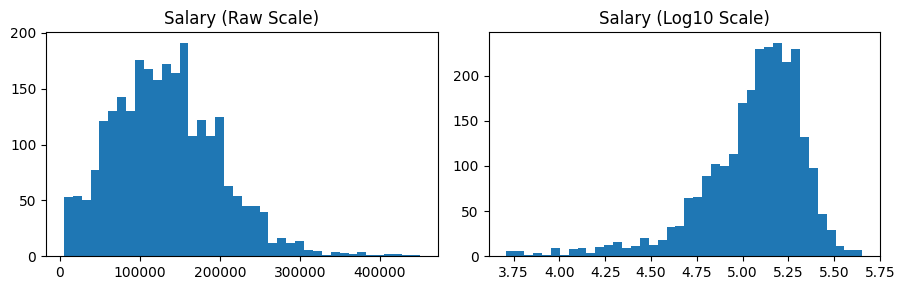

remote_ratio
Fully remote    1211
On-site         1186
Hybrid           187
Name: count, dtype: int64

In [232]:
# Numerical columns
num_cols = ["work_year", "salary_in_usd"]

# Descriptive statistics
display(df[num_cols].describe().T)

# Skewness
display(df[num_cols].skew().round(2))

# Salary distribution: raw vs log scale
salary = df["salary_in_usd"].dropna()
salary = salary[salary > 0]

fig, ax = plt.subplots(1, 2, figsize=(9, 3))

ax[0].hist(salary, bins=40)
ax[0].set_title("Salary (Raw Scale)")

ax[1].hist(np.log10(salary), bins=40)
ax[1].set_title("Salary (Log10 Scale)")

plt.tight_layout()
plt.show()

# Categorical distribution of remote work
display(df["remote_ratio"].value_counts(dropna=False))

# Step 5 : Detect and Judge Outliers

In [233]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - k * iqr, q3 + k * iqr
    return s[(s < low) | (s > high)], low, high

In [234]:
# Detect salary outliers
salary = df["salary_in_usd"].dropna()

out, low, high = iqr_outliers(salary)

print(f"{len(out)} values outside [{low:.0f}, {high:.0f}] USD")

# Inspect the actual rows before deciding anything
display(
    df.loc[out.index]
    .sort_values("salary_in_usd", ascending=False)
    .head(10)
)

29 values outside [-50062, 310038] USD


,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
3522,2020,MI,FT,Research Scientist,450000,US,On-site,US,M
2011,2022,MI,FT,Data Analyst,430967,GB,On-site,GB,M
528,2023,SE,FT,AI Scientist,423834,IL,On-site,IL,L
3747,2021,MI,FT,Applied Machine Learning Scientist,423000,US,Hybrid,US,L
3675,2021,EX,CT,Principal Data Scientist,416000,US,Fully remote,US,S
3750,2020,SE,FT,Data Scientist,412000,US,Fully remote,US,L
3463,2022,SE,FT,Data Analytics Lead,405000,US,Fully remote,US,L
1288,2023,SE,FT,Data Analyst,385000,US,On-site,US,M
3468,2022,SE,FT,Applied Data Scientist,380000,US,Fully remote,US,L
649,2023,SE,FT,Data Architect,376080,US,Fully remote,US,M


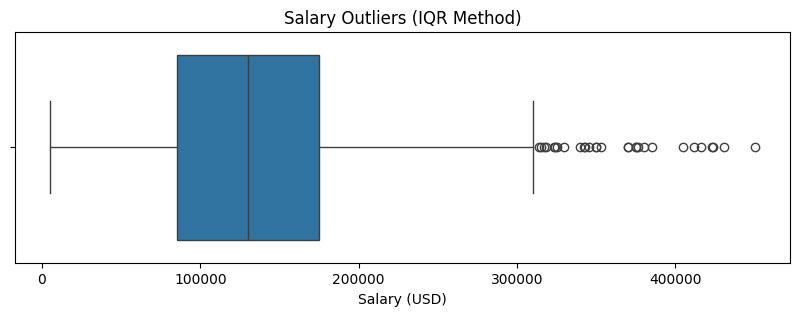

In [235]:
# Boxplot to visualize outliers
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["salary_in_usd"])
plt.title("Salary Outliers (IQR Method)")
plt.xlabel("Salary (USD)")
plt.show()

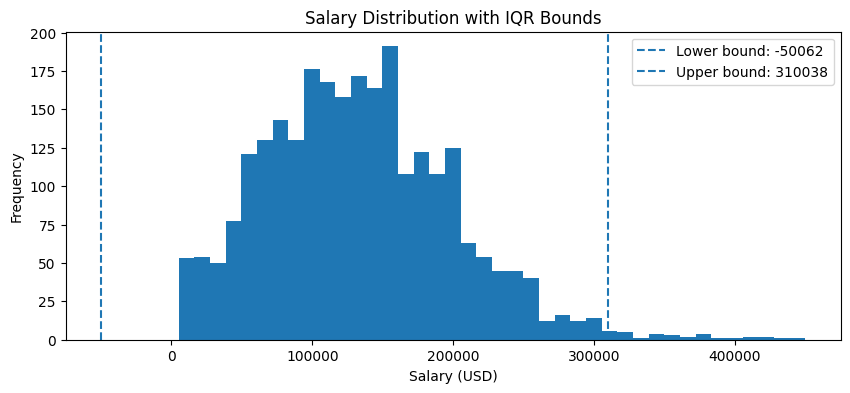

In [236]:
# Histogram with IQR boundaries
plt.figure(figsize=(10, 4))
plt.hist(df["salary_in_usd"].dropna(), bins=40)

plt.axvline(low, linestyle="--", label=f"Lower bound: {low:.0f}")
plt.axvline(high, linestyle="--", label=f"Upper bound: {high:.0f}")

plt.title("Salary Distribution with IQR Bounds")
plt.xlabel("Salary (USD)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

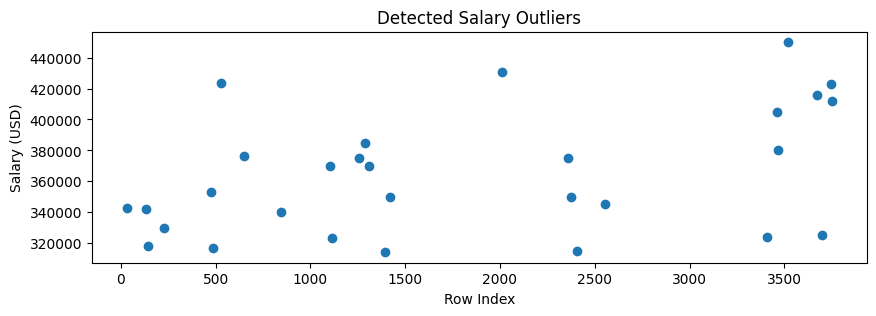

In [237]:
# Plot outlier salaries only
plt.figure(figsize=(10, 3))
plt.scatter(out.index, out.values)
plt.title("Detected Salary Outliers")
plt.xlabel("Row Index")
plt.ylabel("Salary (USD)")
plt.show()


# Step 6 : Study Categorical Variables

In [238]:

# Categorical columns
cat_cols = [
    "experience_level",
    "employment_type",
    "job_title",
    "employee_residence",
    "company_location",
    "company_size",
    "remote_ratio"
]

# Explore category counts and percentages
for c in cat_cols:
    print(f"\n{'=' * 50}")
    print(f"Column: {c}")
    print(f"Number of categories: {df[c].nunique(dropna=False)}")

    print(
        df[c]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(1)
    )



Column: experience_level
Number of categories: 4
experience_level
SE    60.1
MI    25.7
EN    10.4
EX     3.7
Name: proportion, dtype: float64

Column: employment_type
Number of categories: 4
employment_type
FT    98.6
PT     0.7
CT     0.4
FL     0.4
Name: proportion, dtype: float64

Column: job_title
Number of categories: 93
job_title
Data Engineer                23.1
Data Scientist               20.8
Data Analyst                 15.3
Machine Learning Engineer     8.0
Analytics Engineer            3.5
                             ... 
Principal Data Architect      0.0
Head of Machine Learning      0.0
Cloud Data Architect          0.0
Staff Data Scientist          0.0
Finance Data Analyst          0.0
Name: proportion, Length: 93, dtype: float64

Column: employee_residence
Number of categories: 78
employee_residence
US    73.3
GB     5.8
CA     3.1
IN     2.7
DE     1.8
      ... 
RS     0.0
NZ     0.0
MD     0.0
LU     0.0
MT     0.0
Name: proportion, Length: 78, dtype: float64

Co

In [239]:

# Group rare job titles (< 2%) into "Other"

freq = df["job_title"].value_counts(normalize=True)

rare = freq[freq < 0.02].index

df["job_title_grouped"] = df["job_title"].where(
    ~df["job_title"].isin(rare),
    "Other"
)

# Check the new distribution
print(
    df["job_title_grouped"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(1)
)


job_title_grouped
Data Engineer                23.1
Other                        22.2
Data Scientist               20.8
Data Analyst                 15.3
Machine Learning Engineer     8.0
Analytics Engineer            3.5
Research Scientist            2.5
Data Architect                2.5
Data Science Manager          2.0
Name: proportion, dtype: float64


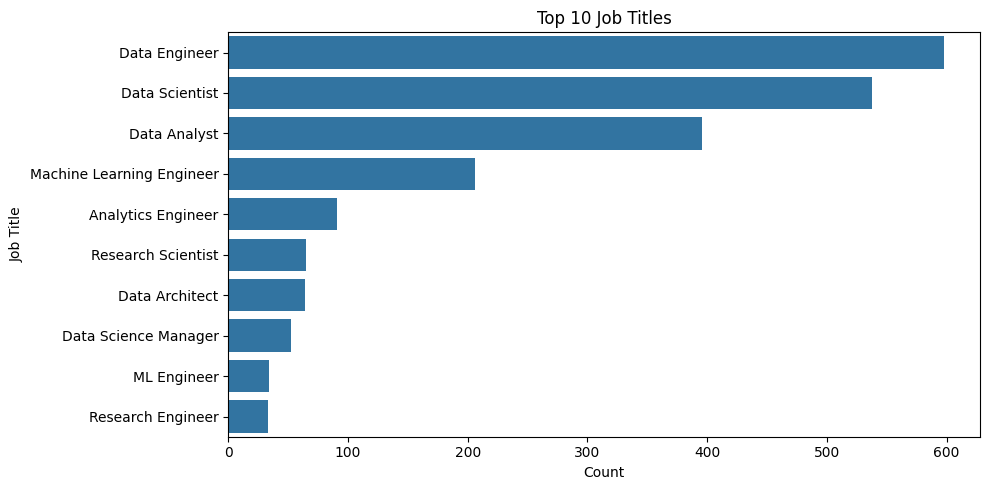

In [240]:

# Plot Top 10 job titles

top_10_jobs = df["job_title"].value_counts().head(10).index

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df[df["job_title"].isin(top_10_jobs)],
    y="job_title",
    order=top_10_jobs
)

plt.title("Top 10 Job Titles")
plt.xlabel("Count")
plt.ylabel("Job Title")

plt.tight_layout()
plt.show()


# Step 7 : Explore Relationships Between Two Variables

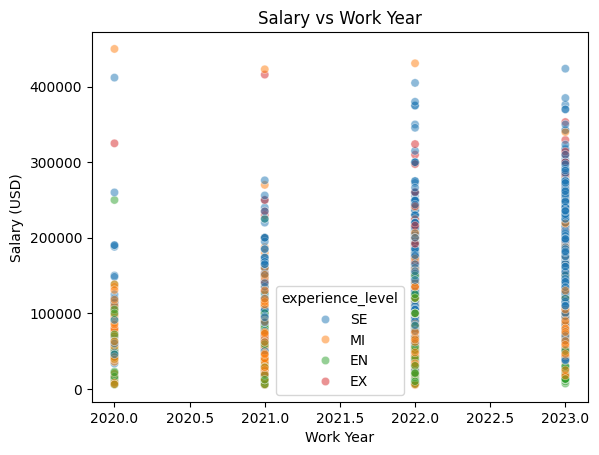

               work_year  salary_in_usd
work_year           1.00           0.24
salary_in_usd       0.24           1.00


In [241]:
# Scatter Plot

sns.scatterplot(
    data=df,
    x="work_year",
    y="salary_in_usd",
    hue="experience_level",
    alpha=0.5
)

plt.title("Salary vs Work Year")
plt.xlabel("Work Year")
plt.ylabel("Salary (USD)")
plt.show()

# Correlation coefficient
print(df[["work_year", "salary_in_usd"]].corr().round(2))

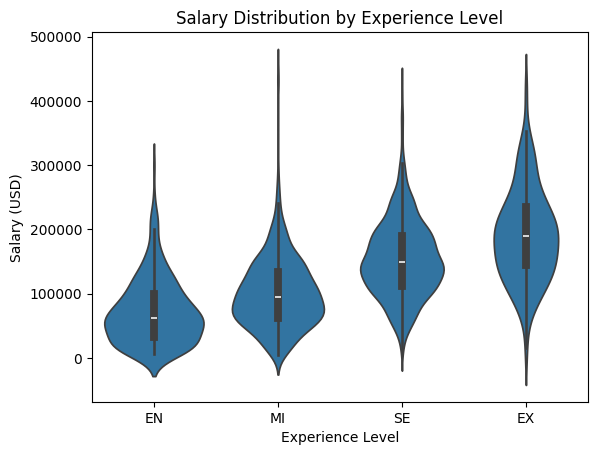

,count,mean,median
experience_level,,,
EN,270,72648.69,61900.0
EX,96,191078.21,189618.5
MI,664,101828.78,95000.0
SE,1554,153897.44,148800.0


In [242]:
# Violin Plot

sns.violinplot(
    data=df,
    x="experience_level",
    y="salary_in_usd",
    order=["EN", "MI", "SE", "EX"]
)

plt.title("Salary Distribution by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Salary (USD)")
plt.show()

# Mean and median salary per experience level
display(
    df.groupby("experience_level", observed=True)["salary_in_usd"]
    .agg(["count", "mean", "median"])
    .round(2)
)

In [243]:
pd.crosstab(
    df["experience_level"],
    df["employment_type"],
    normalize="index"
).mul(100).round(1)

employment_type,CT,FL,FT,PT
experience_level,,,,
EN,0.7,0.7,93.3,5.2
EX,1.0,0.0,99.0,0.0
MI,0.8,0.8,98.0,0.5
SE,0.1,0.2,99.7,0.0


# Step 8 : Measure Correlation, and Distrust It

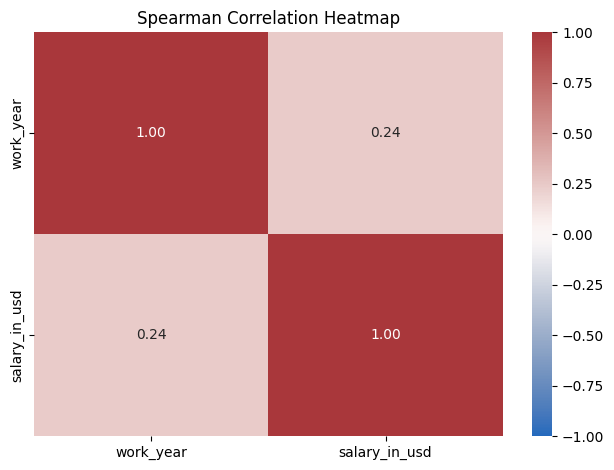

work_year    0.23763
Name: salary_in_usd, dtype: float64

In [244]:

# Select numerical columns
num_cols = ["work_year", "salary_in_usd"]

# Spearman correlation (rank-based)
corr = df[num_cols].corr(method="spearman")

# Plot correlation heatmap
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

# Rank variables by their relationship with salary
corr["salary_in_usd"].drop("salary_in_usd").sort_values(
    ascending=False
)


# Step 9 : Look for Patterns Over Time

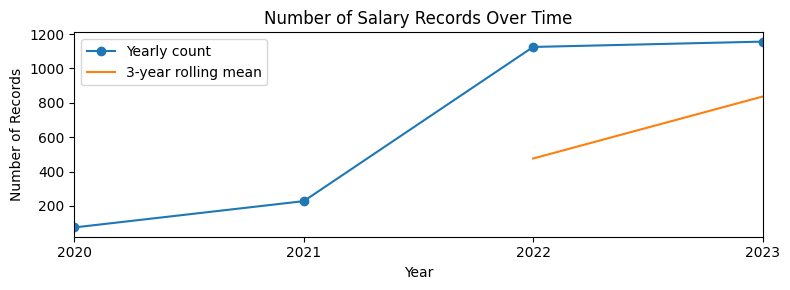

In [245]:

# Convert work_year to datetime
df["work_year"] = pd.to_datetime(
    df["work_year"].astype(str),
    format="%Y"
)

# Count salary records per year
yearly = (
    df.set_index("work_year")
    .resample("YS")
    .size()
)

# Plot yearly counts and rolling mean
fig, ax = plt.subplots(figsize=(8, 3))

yearly.plot(ax=ax, label="Yearly count", marker="o")
yearly.rolling(3).mean().plot(
    ax=ax,
    label="3-year rolling mean"
)

ax.set_title("Number of Salary Records Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Records")
ax.legend()

plt.tight_layout()
plt.show()


# Step 10 : Compare Segments Against the Target

In [246]:

# Overall median salary
overall = df["salary_in_usd"].median()

# Salary statistics by experience level
by_exp = df.groupby("experience_level", observed=True)["salary_in_usd"].agg(
    median="median",
    mean="mean",
    n="count"
)

print(f"Overall median salary: ${overall:,.0f}")
print(by_exp.sort_values("median", ascending=False).round(2))


Overall median salary: $130,000
                    median       mean     n
experience_level                           
EX                189618.5  191078.21    96
SE                148800.0  153897.44  1554
MI                 95000.0  101828.78   664
EN                 61900.0   72648.69   270


In [247]:

# Create salary bands
df["salary_band"] = pd.cut(
    df["salary_in_usd"],
    bins=[-1, 50000, 100000, 150000, float("inf")],
    labels=["0-50K", "50K-100K", "100K-150K", "150K+"]
)

# Count records in each salary band
print(df["salary_band"].value_counts(sort=False, dropna=False))


salary_band
0-50K        256
50K-100K     611
100K-150K    788
150K+        929
Name: count, dtype: int64


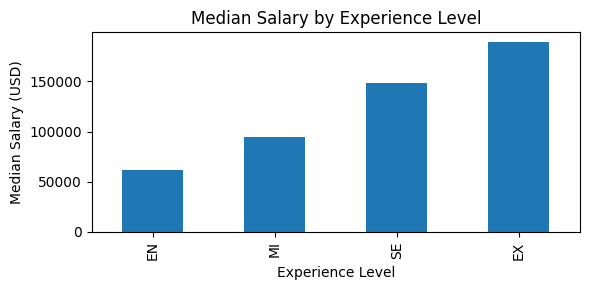

In [248]:

fig, ax = plt.subplots(figsize=(6, 3))

df.groupby(
    "experience_level",
    observed=True
)["salary_in_usd"].median().sort_values().plot.bar(ax=ax)

ax.set_title("Median Salary by Experience Level")
ax.set_xlabel("Experience Level")
ax.set_ylabel("Median Salary (USD)")

plt.tight_layout()
plt.show()


# Step 11 : Summarise and Document

In [249]:
# Data and quality
print("=== Data Quality ===")
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Duplicate rows remaining: {df.duplicated().sum()}")

missing = df.isna().mean().mul(100).round(1)
print("\nMissing values (%):")
print(missing[missing > 0])

print("\nSalary statistics:")
print(df["salary_in_usd"].describe().round(2))

# Key patterns
print("\n=== Salary by Experience Level ===")
by_exp = df.groupby("experience_level", observed=True)[
    "salary_in_usd"
].agg(["count", "median", "mean"]).round(2)

print(by_exp.sort_values("median", ascending=False))

print("\nOverall median salary:",
      f"${df['salary_in_usd'].median():,.0f}")

# Hypotheses: work year and salary
print("\n=== Spearman Correlation ===")
print(
    df[["work_year", "salary_in_usd"]]
    .corr(method="spearman")
    .round(2)
)

# Outliers
salary = df["salary_in_usd"].dropna()
out, low, high = iqr_outliers(salary)

print("\n=== Outlier Assessment ===")
print(f"IQR lower bound: ${low:,.0f}")
print(f"IQR upper bound: ${high:,.0f}")
print(f"Potential outliers: {len(out):,} ({len(out)/len(salary)*100:.1f}%)")

# Salary by remote work arrangement
print("\n=== Salary by Remote Work ===")
print(
    df.groupby("remote_ratio", observed=True)["salary_in_usd"]
    .agg(["count", "median", "mean"])
    .round(2)
    .sort_values("median", ascending=False)
)


=== Data Quality ===
Rows: 2,584
Columns: 11
Duplicate rows remaining: 0

Missing values (%):
Series([], dtype: float64)

Salary statistics:
count      2584.00
mean     133409.28
std       67136.84
min        5132.00
25%       84975.00
50%      130000.00
75%      175000.00
max      450000.00
Name: salary_in_usd, dtype: float64

=== Salary by Experience Level ===
                  count    median       mean
experience_level                            
EX                   96  189618.5  191078.21
SE                 1554  148800.0  153897.44
MI                  664   95000.0  101828.78
EN                  270   61900.0   72648.69

Overall median salary: $130,000

=== Spearman Correlation ===
               work_year  salary_in_usd
work_year           1.00           0.24
salary_in_usd       0.24           1.00

=== Outlier Assessment ===
IQR lower bound: $-50,062
IQR upper bound: $310,038
Potential outliers: 29 (1.1%)

=== Salary by Remote Work ===
              count    median       mean


## 1. Data Quality
- **Rows:** 2,584
- **Columns:** 11
- **Duplicate rows remaining:** 0
- **Missing values:** None reported in the output.

## 2. Salary Statistics

| Statistic | Value (USD) |
|---|---:|
| Count | 2,584 |
| Mean | 133,409.28 |
| Standard Deviation | 67,136.84 |
| Minimum | 5,132.00 |
| 25th Percentile (Q1) | 84,975.00 |
| Median (Q2) | 130,000.00 |
| 75th Percentile (Q3) | 175,000.00 |
| Maximum | 450,000.00 |

### Key Observations
- The **median salary is $130,000**, while the mean is $133,409.28.
- Salaries range from **$5,132 to $450,000**.
- The standard deviation of $67,136.84 indicates substantial variation in salaries.

## 3. Salary by Experience Level

| Experience Level | Count | Median Salary (USD) | Mean Salary (USD) |
|---|---:|---:|---:|
| Executive (EX) | 96 | 189,618.50 | 191,078.21 |
| Senior (SE) | 1,554 | 148,800.00 | 153,897.44 |
| Mid-level (MI) | 664 | 95,000.00 | 101,828.78 |

**Observation:** Executive-level employees have the highest median and mean salaries among the displayed groups, followed by senior and mid-level employees.

## 4. Salary by Remote Work Arrangement

| Remote Arrangement | Count | Median Salary (USD) | Mean Salary (USD) |
|---|---:|---:|---:|
| On-site | 1,186 | 137,500.00 | 143,690.17 |
| Fully remote | 1,211 | 130,000.00 | 131,821.67 |
| Hybrid | 187 | 63,312.00 | 78,486.61 |

**Observation:** On-site roles have the highest median and mean salaries in this dataset, while hybrid roles have the lowest.

## 5. Limitations and Next Steps

- Salary differences show associations, not necessarily causal relationships.
- Job title, experience, location, company size, and other factors may influence salary.
- Investigate unusually low or high salaries before deciding whether they represent errors.
- Compare salary distributions across job titles, company locations, and company sizes.
- Consider the number of records in each group when interpreting comparisons.